In [2]:
import sys  # lets us change where Python looks for modules
sys.path.append("..")  # add the project root so we can import from src/

import pandas as pd  # tables and time series
import numpy as np  # math on arrays
import matplotlib.pyplot as plt  # plotting

from src.data import load_raw, make_weekly_table  # your Day 1 data functions

raw = load_raw("../data/superstore.csv")  # read the raw Superstore CSV
weekly = make_weekly_table(raw)  # weekly sales for your 9 sub-categories (data.py does the filtering)

print(weekly.shape)  # should print (209, 9)
weekly.head()  # show the first 5 weeks to check it looks right

(209, 9)


Sub-Category,Phones,Chairs,Storage,Binders,Accessories,Appliances,Furnishings,Paper,Tables
2015-01-04,0.00,0.00,272.736,3.540,0.00,0.000,0.000,16.448,0.0
2015-01-11,1147.94,2573.82,0.000,620.410,31.20,0.000,138.608,25.980,0.0
2015-01-18,124.20,545.94,1898.430,27.666,796.69,64.864,127.104,37.408,0.0
2015-01-25,699.93,1067.94,80.560,148.284,0.00,247.716,345.570,115.504,0.0
2015-02-01,343.33,0.00,777.090,14.608,468.90,0.000,75.240,46.680,333.0


In [3]:
summary = pd.DataFrame({  # build a small table with one row per sub-category
    "total_sales": weekly.sum(),  # total sales over all 209 weeks
    "mean_weekly": weekly.mean(),  # average sales per week
    "zero_weeks": (weekly == 0).sum(),  # how many weeks had no sales at all
})  # end of the table
summary = summary.sort_values("total_sales", ascending=False).round(0)  # biggest sub-category first, no decimals
print(summary)  # show the table

SARIMA_CATS = summary.index[:4].tolist()  # keep the 4 biggest sub-categories for SARIMA
print(SARIMA_CATS)  # show which ones were picked

              total_sales  mean_weekly  zero_weeks
Sub-Category                                      
Phones           327782.0       1568.0          15
Chairs           322541.0       1543.0          30
Storage          219343.0       1049.0          12
Tables           202811.0        970.0          61
Binders          200029.0        957.0           1
Accessories      164187.0        786.0          15
Appliances       104618.0        501.0          35
Furnishings       89212.0        427.0           6
Paper             76828.0        368.0           4
['Phones', 'Chairs', 'Storage', 'Tables']


In [4]:
SARIMA_CATS = ["Phones", "Chairs", "Storage", "Binders"]  # top 4 by sales, with Binders replacing Tables (61 zero weeks)
print(SARIMA_CATS)  # check the final list

['Phones', 'Chairs', 'Storage', 'Binders']


In [7]:
%load_ext autoreload
%autoreload 2
from src.stat_models import sarima_all  # the new SARIMA function
from src.validation import walk_forward_splits  # Day 2 fold function
from src.metrics import mae  # Day 2 metric

w4 = weekly[SARIMA_CATS]  # only the 4 sub-categories picked for SARIMA
train_idx, test_idx = next(walk_forward_splits(len(w4)))  # take only the first fold
w_train = w4.iloc[train_idx]  # weeks 1 to 169
w_test = w4.iloc[test_idx]  # weeks 170 to 177 (the real answers)

pred = sarima_all(w_train, horizon=len(test_idx))  # forecast 8 weeks for the 4 categories
print((pred.index == w_test.index).all())  # True means the forecast dates match the test dates
print(pred.round(0))  # the 8 forecast weeks for each category
print(mae(w_test.values.ravel(), pred.values.ravel()))  # fold 1 MAE across the 4 categories

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
True
            Phones  Chairs  Storage  Binders
2018-04-01  1255.0   475.0    714.0    866.0
2018-04-08  1258.0  1089.0    726.0    880.0
2018-04-15  1340.0  1130.0    778.0    902.0
2018-04-22  1424.0  1237.0    828.0    926.0
2018-04-29  1495.0  1321.0    869.0    950.0
2018-05-06  1546.0  1387.0    899.0    973.0
2018-05-13  1575.0  1430.0    917.0    994.0
2018-05-20  1581.0  1448.0    923.0   1011.0
802.4720429863669


In [8]:
from src.evaluate import evaluate  # the Day 3 scoring loop (same folds as baselines and LightGBM)

res_sarima = evaluate(w4, sarima_all, "sarima")  # run all 5 folds on the 4 SARIMA categories (takes ~10-30 seconds)
print(res_sarima.shape)  # expect (20, 7): 5 folds x 4 categories
print(res_sarima[["mae", "rmse", "smape", "mase"]].mean().round(2))  # average over folds and categories
print(res_sarima.groupby("category")["mae"].mean().round(0))  # MAE per category
print(res_sarima.groupby("fold")["mae"].mean().round(0))  # MAE per fold, to see which folds are hardest

res_sarima.to_csv("../results/sarima_scores_by_fold.csv", index=False)  # save the detailed scores

(20, 7)
mae      1171.33
rmse     1531.33
smape      75.44
mase        0.98
dtype: float64
category
Binders    1090.0
Chairs     1320.0
Phones     1287.0
Storage     988.0
Name: mae, dtype: float64
fold
1     802.0
2     837.0
3    1336.0
4    1400.0
5    1481.0
Name: mae, dtype: float64


In [9]:
metrics = ["mae", "rmse", "smape", "mase"]  # the four score columns
day3 = pd.read_csv("../results/all_scores_by_fold.csv")  # Day 3 scores: baselines + both LightGBM, per fold and category
all_fold = pd.concat([day3, res_sarima], ignore_index=True)  # add SARIMA's rows to the same table

fair = all_fold[all_fold["category"].isin(SARIMA_CATS)]  # keep only the 4 categories SARIMA was run on
table_4 = fair.groupby("model")[metrics].mean().sort_values("mae").round(2).reset_index()  # average per model, best MAE first
print("Same 4 categories (Phones, Chairs, Storage, Binders):")  # title for the first table
print(table_4)  # every model, compared fairly

table_9 = day3.groupby("model")[metrics].mean().sort_values("mae").round(2).reset_index()  # Day 3 models on all 9 categories
print("\nAll 9 categories (SARIMA not included):")  # title for the second table
print(table_9)  # the Day 3 table, for reference

by_cat = all_fold.groupby(["category", "model"])[metrics].mean().round(2).reset_index()  # average per model and category

all_fold.to_csv("../results/all_models_by_fold.csv", index=False)  # save every score row (Day 3 files stay untouched)
table_4.to_csv("../results/all_models_4cats.csv", index=False)  # save the fair 4-category comparison
by_cat.to_csv("../results/all_models_by_category.csv", index=False)  # save the per-category table

Same 4 categories (Phones, Chairs, Storage, Binders):
               model      mae     rmse  smape  mase
0        lgbm_global  1162.60  1554.02  75.24  0.98
1             sarima  1171.33  1531.33  75.44  0.98
2  lgbm_per_category  1331.83  1741.54  86.00  1.11
3       moving_avg_4  1340.82  1644.21  81.87  1.12
4              naive  1410.50  1785.13  81.64  1.15
5     seasonal_naive  1529.87  2009.03  95.85  1.28

All 9 categories (SARIMA not included):
               model      mae     rmse  smape  mase
0        lgbm_global   867.22  1132.52  75.92  1.07
1  lgbm_per_category   986.14  1260.29  89.54  1.23
2       moving_avg_4   987.32  1205.53  82.88  1.23
3     seasonal_naive  1127.14  1460.40  98.48  1.38
4              naive  1133.06  1384.60  91.14  1.45


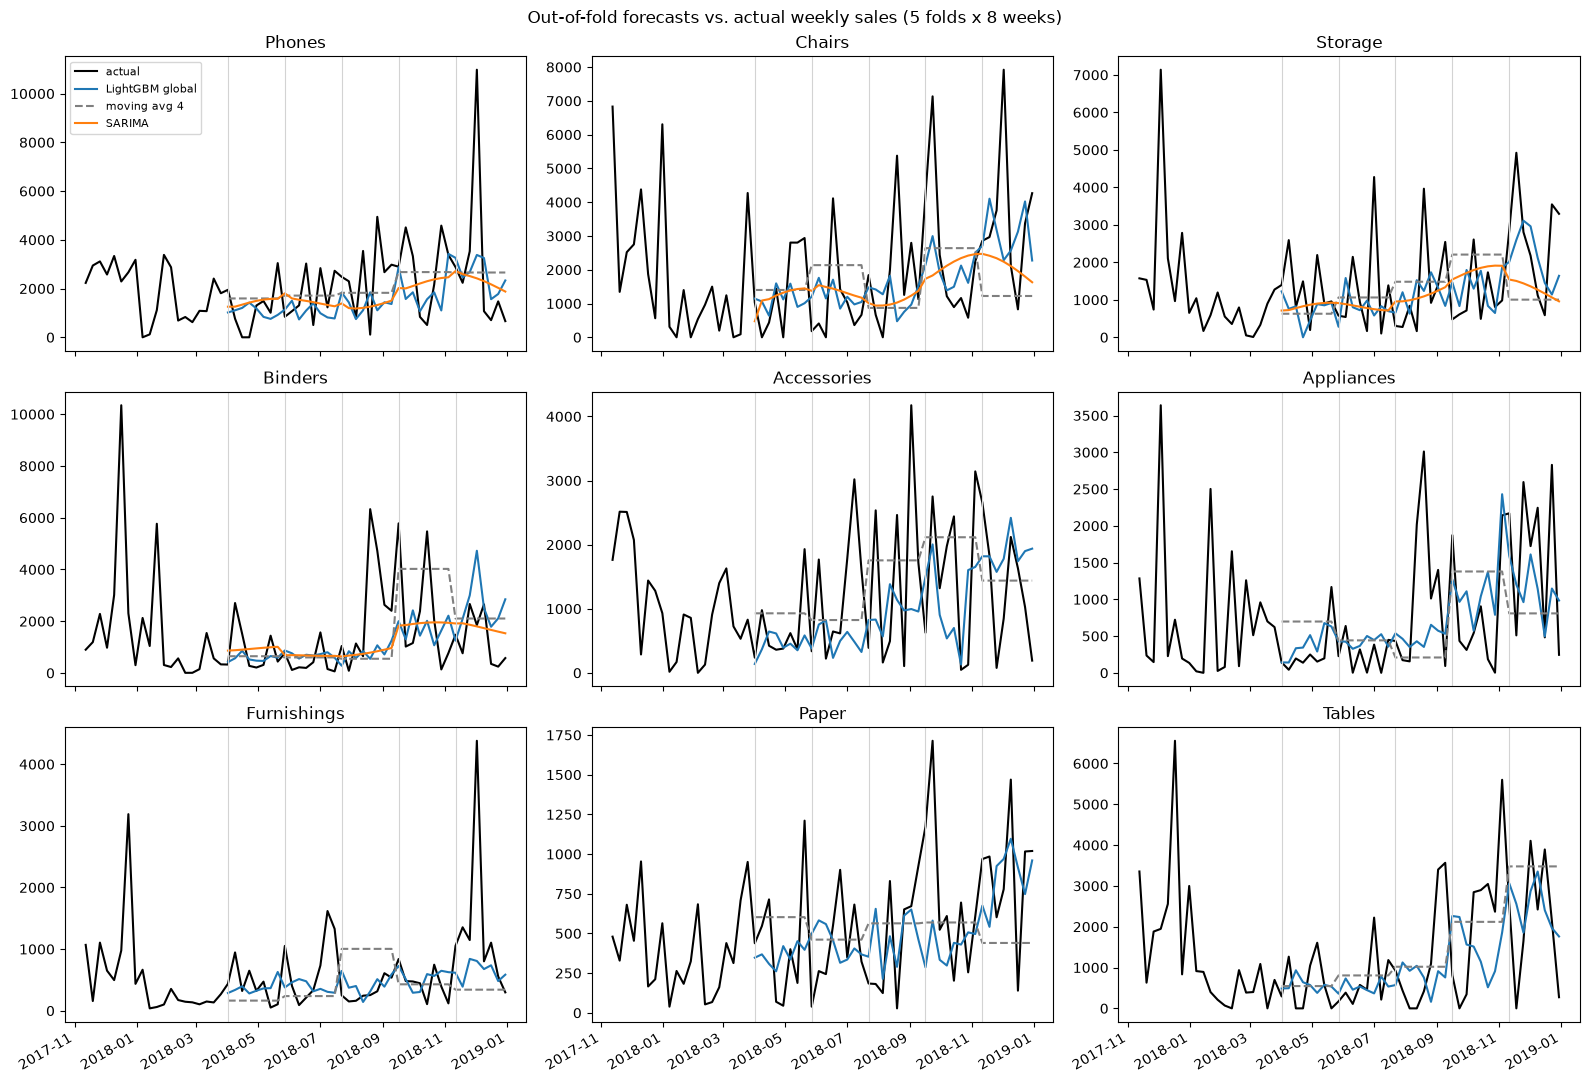

In [10]:
from src.models import global_forecast  # Day 3 global LightGBM (train + forecast)
from src.baselines import moving_average  # Day 2 moving-average baseline (works on one series)


def ma4_all(weekly_train, horizon):  # moving average for every column, returned as a wide table like the other models
    future_index = pd.date_range(weekly_train.index[-1] + pd.Timedelta(weeks=1), periods=horizon, freq="W")  # dates of the forecast weeks
    preds = {cat: moving_average(weekly_train[cat], horizon) for cat in weekly_train.columns}  # forecast each category
    return pd.DataFrame(preds, index=future_index)  # wide table: forecast weeks x categories


def collect_preds(data, forecast_fn):  # run all 5 folds and keep the forecasts (not just the scores)
    parts = []  # one forecast table per fold
    for fold, (train_idx, test_idx) in enumerate(walk_forward_splits(len(data)), start=1):  # same 5 folds as always
        pred = forecast_fn(data.iloc[train_idx], len(test_idx))  # forecast the next 8 weeks
        pred["fold"] = fold  # remember which fold these weeks belong to
        parts.append(pred)  # store this fold's forecast
    return pd.concat(parts)  # stack the 5 folds: 40 forecast weeks in total


pred_lgbm = collect_preds(weekly, global_forecast)  # LightGBM forecasts for all 9 categories (takes a few seconds)
pred_ma4 = collect_preds(weekly, ma4_all)  # moving-average forecasts for all 9 categories
pred_sarima = collect_preds(w4, sarima_all)  # SARIMA forecasts for the 4 big categories

fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)  # 3x3 grid, one panel per category, same date axis
start = pred_lgbm.index.min() - pd.Timedelta(weeks=20)  # show 20 weeks of history before the first test week
for ax, cat in zip(axes.ravel(), weekly.columns):  # loop over panels and categories together
    ax.plot(weekly.loc[start:, cat], color="black", lw=1.5, label="actual")  # real weekly sales
    ax.plot(pred_lgbm[cat], color="tab:blue", label="LightGBM global")  # LightGBM forecasts
    ax.plot(pred_ma4[cat], color="tab:gray", ls="--", label="moving avg 4")  # baseline forecasts
    if cat in pred_sarima.columns:  # SARIMA exists only for the 4 big categories
        ax.plot(pred_sarima[cat], color="tab:orange", label="SARIMA")  # SARIMA forecasts
    for d in pred_lgbm[pred_lgbm["fold"].diff() != 0].index:  # the first week of each fold
        ax.axvline(d, color="lightgray", lw=0.8)  # thin line marking where each fold starts
    ax.set_title(cat)  # category name above the panel
axes[0, 0].legend(fontsize=8)  # one legend is enough (same colours everywhere)
fig.suptitle("Out-of-fold forecasts vs. actual weekly sales (5 folds x 8 weeks)")  # title for the whole figure
fig.autofmt_xdate()  # tilt the dates so they don't overlap
plt.tight_layout()  # stop labels from being cut off
plt.savefig("../results/forecast_vs_actual.png", dpi=150)  # save next to your feature-importance plot
plt.show()  # display it in the notebook

oof = pd.concat({"lgbm_global": pred_lgbm, "moving_avg_4": pred_ma4, "sarima": pred_sarima}, names=["model", "date"])  # all forecasts in one table
oof.to_csv("../results/oof_predictions.csv")  # save them for the error analysis in the next step

In [11]:
actual = weekly.loc[pred_lgbm.index]  # real sales for the 40 test weeks, all 9 categories
err = (pred_lgbm[weekly.columns] - actual).abs()  # LightGBM absolute error per week and category

long = err.stack().rename("abs_err").reset_index()  # one row per (week, category) with its error
long.columns = ["date", "category", "abs_err"]  # name the columns clearly
long["actual"] = actual.stack().values  # add the real sales for that week and category
long["forecast"] = pred_lgbm[weekly.columns].stack().values  # add the LightGBM forecast

cat_mean = weekly.mean()  # each category's average weekly sales over all 209 weeks
cat_std = weekly.std()  # each category's typical week-to-week spread
long["is_spike"] = long["actual"] > (long["category"].map(cat_mean) + 2 * long["category"].map(cat_std))  # spike = more than 2 std above the category average
long["is_q4"] = long["date"].dt.month >= 9  # peak season from your EDA: September to December

print("Spike weeks:", long["is_spike"].sum(), "of", len(long))  # how many test weeks are spikes
print(long.groupby("is_spike")["abs_err"].mean().round(0))  # average error on spike vs normal weeks
spike_share = long.loc[long["is_spike"], "abs_err"].sum() / long["abs_err"].sum() * 100  # share of total error that comes from spikes
print(f"Spikes cause {spike_share:.0f}% of all error")  # print that share

print(long.groupby("is_q4")["abs_err"].mean().round(0))  # average error in Sep-Dec vs the rest of the year

sparse = pd.DataFrame({  # one row per category: how sparse it is vs how badly it is forecast
    "zero_weeks": (weekly == 0).sum(),  # number of weeks with no sales
    "smape": by_cat[by_cat["model"] == "lgbm_global"].set_index("category")["smape"],  # LightGBM percentage error
    "mase": by_cat[by_cat["model"] == "lgbm_global"].set_index("category")["mase"],  # LightGBM error vs naive
}).sort_values("smape", ascending=False)  # worst category first
print(sparse)  # check whether sparse categories have the worst percentage error

print(long.sort_values("abs_err", ascending=False).head(10)[["date", "category", "actual", "forecast", "abs_err", "is_spike"]].round(0))  # the 10 worst weeks

Spike weeks: 39 of 360
is_spike
False     668.0
True     2509.0
Name: abs_err, dtype: float64
Spikes cause 31% of all error
is_q4
False     706.0
True     1065.0
Name: abs_err, dtype: float64
             zero_weeks  smape  mase
Tables               61  97.67  1.13
Binders               1  85.41  1.05
Appliances           35  78.34  1.03
Accessories          15  77.66  1.25
Storage              12  74.16  1.04
Chairs               30  72.33  0.74
Phones               15  69.08  1.07
Furnishings           6  64.58  1.15
Paper                 4  64.04  1.12
          date category   actual  forecast  abs_err  is_spike
315 2018-12-02   Phones  10981.0    3380.0   7602.0      True
183 2018-08-19  Binders   6331.0     547.0   5783.0      True
316 2018-12-02   Chairs   7922.0    2283.0   5639.0      True
181 2018-08-19   Chairs   5377.0     475.0   4902.0      True
226 2018-09-23   Chairs   7133.0    2996.0   4137.0      True
189 2018-08-26   Phones   4944.0    1108.0   3836.0      True
219 

C:\Users\shadows box\AppData\Local\Temp\ipykernel_12596\4155477855.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(long.sort_values("abs_err", ascending=False).head(10)[["date", "category", "actual", "forecast", "abs_err", "is_spike"]].round(0))  # the 10 worst weeks


## Error analysis (global LightGBM, 40 test weeks x 9 categories)

**1. Spikes cause most of the error.** 39 of 360 test weeks (11%) are spikes (more than 2 std above the category average), but they cause 31% of all error. Error on a spike week is 3.8x a normal week (2,509 vs 668). All 10 worst weeks are spikes, e.g. Phones on 2018-12-02 (actual 10,981, forecast 3,380).
*Why:* spikes are single very large orders. Lags and rolling means only describe the past, so nothing in the features can warn the model that a big order is coming. Every model (LightGBM, SARIMA, moving average) misses them.

**2. Q4 is harder.** Error from September to December is about 1.5x the rest of the year (1,065 vs 706), and 9 of the 10 worst weeks fall between July and December.
*Why:* the peak season has larger and more frequent spikes, and the training data contains only 3 previous Q4s to learn from.

**3. Sparse series inflate percentage error.** Tables (61 zero weeks, 29%) has the worst sMAPE (97.7%).
*Why:* a forecast against an actual of 0 always counts as 200% sMAPE. Sparsity is not the only cause, though: Binders has 1 zero week but the second worst sMAPE because of its large August-September orders, and Chairs has 30 zero weeks but the best MASE (0.74).

**4. Each model fails differently.** SARIMA is the smoothest: it follows the yearly wave but no jumps. The moving average lags behind spikes and then overshoots (Binders forecast near 4,000 for a whole fold after a September spike). LightGBM follows level changes best (Chairs and Accessories in Q4).

In [13]:
baselines = ["naive", "seasonal_naive", "moving_avg_4"]  # the three Day 2 baselines
base = by_cat[by_cat["model"].isin(baselines)]  # keep only baseline rows from the per-category table
best_base = base.loc[base.groupby("category")["mae"].idxmin()].set_index("category")  # the baseline with the lowest MAE in each category

lgbm = by_cat[by_cat["model"] == "lgbm_global"].set_index("category")  # LightGBM global scores per category
sarima = by_cat[by_cat["model"] == "sarima"].set_index("category")  # SARIMA scores (only 4 categories)

verdict = pd.DataFrame({  # one row per category
    "best_baseline": best_base["model"],  # which baseline was strongest there
    "baseline_mae": best_base["mae"],  # that baseline's MAE
    "lgbm_mae": lgbm["mae"],  # LightGBM's MAE
    "sarima_mae": sarima["mae"],  # SARIMA's MAE (empty for the 5 smaller categories)
})  # end of the table
verdict["lgbm_gain_%"] = ((verdict["baseline_mae"] - verdict["lgbm_mae"]) / verdict["baseline_mae"] * 100).round(1)  # how much better LightGBM is (negative = worse)
verdict["lgbm_wins"] = verdict["lgbm_mae"] < verdict["baseline_mae"]  # True if LightGBM beats the best baseline
verdict = verdict.sort_values("lgbm_gain_%")  # worst categories for LightGBM first
print(verdict.round(0))  # show the table
print("LightGBM wins in", verdict["lgbm_wins"].sum(), "of", len(verdict), "categories")  # the honest summary line
verdict.to_csv("../results/best_model_verdict.csv")  # save it for the README

              best_baseline  baseline_mae  lgbm_mae  sarima_mae  lgbm_gain_%  \
category                                                                       
Tables         moving_avg_4        1037.0    1067.0         NaN         -3.0   
Binders               naive        1162.0    1182.0      1090.0         -2.0   
Phones         moving_avg_4        1275.0    1286.0      1287.0         -1.0   
Accessories    moving_avg_4         874.0     850.0         NaN          3.0   
Paper          moving_avg_4         345.0     312.0         NaN         10.0   
Storage        moving_avg_4        1166.0     979.0       988.0         16.0   
Appliances   seasonal_naive         661.0     530.0         NaN         20.0   
Chairs         moving_avg_4        1602.0    1204.0      1320.0         25.0   
Furnishings    moving_avg_4         541.0     396.0         NaN         27.0   

             lgbm_wins  
category                
Tables           False  
Binders          False  
Phones           Fa

## Best model and where it does not win

**Best model: global LightGBM.** Lowest average MAE across all 9 sub-categories (867 vs 987 for the best baseline, about 12% better). It beats the best baseline of each category in 6 of 9 sub-categories, with the biggest gains on Furnishings (+27%), Chairs (+25%), Appliances (+20%) and Storage (+16%).

**Where it does not beat the baseline:**
- **Tables** (-3% vs 4-week moving average): the sparsest series (61 zero weeks) with very large single orders; there is little stable pattern for the model to learn.
- **Binders** (-2% vs naive): large August-September orders dominate the error. SARIMA does best here (MAE 1,090).
- **Phones** (-1% vs 4-week moving average): effectively a tie; the December 2018 spike (10,981) dominates the error.

**Accessories** is a win, but only by 3%, which is close to a tie.

**SARIMA vs LightGBM:** on the 4 largest series they are tied (MAE 1,171 vs 1,163; MASE 0.98 for both). LightGBM is kept as the main model because one model covers all 9 sub-categories, while SARIMA needs a separate fit per series.

**Honest limitation:** MASE is still above 1 for 8 of 9 categories (only Chairs is below 1). Weekly sales per sub-category are dominated by unpredictable large orders, so no model built only on past sales can forecast them well.